<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Build a SimpleRNN and Extract Weights
We will construct a simple RNN model in Keras with 3 hidden units processing a sequence of length 5 (dimensionality 4), then extract the weights: input weights ($W_{xh}$), recurrent weights ($W_{hh}$), and biases ($b_h$).

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.models import Sequential

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Define dimensions
time_steps = 5
input_dim = 4
hidden_units = 3
output_dim = 2

# Build the Keras model with a SimpleRNN layer and a Dense output layer
model = Sequential([
    SimpleRNN(hidden_units, input_shape=(time_steps, input_dim), return_sequences=True, name='rnn_layer'),
    Dense(output_dim, name='dense_output')
])

model.build(input_shape=(None, time_steps, input_dim))

# Extract weights
rnn_layer = model.get_layer('rnn_layer')
dense_layer = model.get_layer('dense_output')

# Keras SimpleRNN returns [W_xh, W_hh, b_h]
weights_rnn = rnn_layer.get_weights()
W_xh = weights_rnn[0]
W_hh = weights_rnn[1]
b_h = weights_rnn[2]

# Dense layer weights [W_hy, b_y]
weights_dense = dense_layer.get_weights()
W_hy = weights_dense[0]
b_y = weights_dense[1]

print("W_xh (Input-to-Hidden Weights) Shape:", W_xh.shape)
print("W_hh (Recurrent Weights) Shape:", W_hh.shape)
print("b_h (Hidden Bias) Shape:", b_h.shape)
print("W_hy (Hidden-to-Output Weights) Shape:", W_hy.shape)

W_xh (Input-to-Hidden Weights) Shape: (4, 3)
W_hh (Recurrent Weights) Shape: (3, 3)
b_h (Hidden Bias) Shape: (3,)
W_hy (Hidden-to-Output Weights) Shape: (3, 2)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Task 2: Manual Hidden State Computation vs Keras
We will manually trace and compute the hidden states for a sample input sequence and compare our results directly to the outputs computed by Keras.

In [2]:
# Create a dummy 5-word input sentence represented by 5 vectors of dimension 4
sample_input = np.random.randn(1, time_steps, input_dim).astype(np.float32)

# 1. Compute hidden states via Keras
keras_rnn_output = rnn_layer(sample_input).numpy()[0]

# 2. Compute hidden states manually
manual_h = []
h_t = np.zeros((hidden_units,), dtype=np.float32) # Initial state h_0

x_seq = sample_input[0] # Shape: (5, 4)

for t in range(time_steps):
    x_t = x_seq[t]
    # SimpleRNN formula: h_t = tanh(x_t * W_xh + h_{t-1} * W_hh + b_h)
    h_t = np.tanh(np.dot(x_t, W_xh) + np.dot(h_t, W_hh) + b_h)
    manual_h.append(h_t)

manual_h = np.array(manual_h)

# Compare outputs
print("Keras Hidden States:\n", keras_rnn_output)
print("\nManual Hidden States:\n", manual_h)
print("\nMaximum Absolute Difference:", np.max(np.abs(keras_rnn_output - manual_h)))

Keras Hidden States:
 [[ 0.95831484 -0.20891052 -0.53826016]
 [ 0.9911943  -0.83658093 -0.5781069 ]
 [ 0.23401092  0.44488746  0.9223597 ]
 [-0.99012065 -0.9226098  -0.916688  ]
 [-0.98215353  0.97165173  0.9749689 ]]

Manual Hidden States:
 [[ 0.95831484 -0.20891054 -0.53826016]
 [ 0.9911943  -0.83658093 -0.5781069 ]
 [ 0.23401093  0.44488734  0.92235965]
 [-0.9901206  -0.9226098  -0.916688  ]
 [-0.9821534   0.9716517   0.97496885]]

Maximum Absolute Difference: 1.1920929e-07


# Task 3 & 4: Visualizing the Unfolded Network with NetworkX
Now, we'll map the unrolled network over 5 steps. We create input nodes ($x_1 \dots x_5$), hidden state nodes ($h_1 \dots h_5$), and output nodes ($y_1 \dots y_5$), and label their connections with the shared parameters.

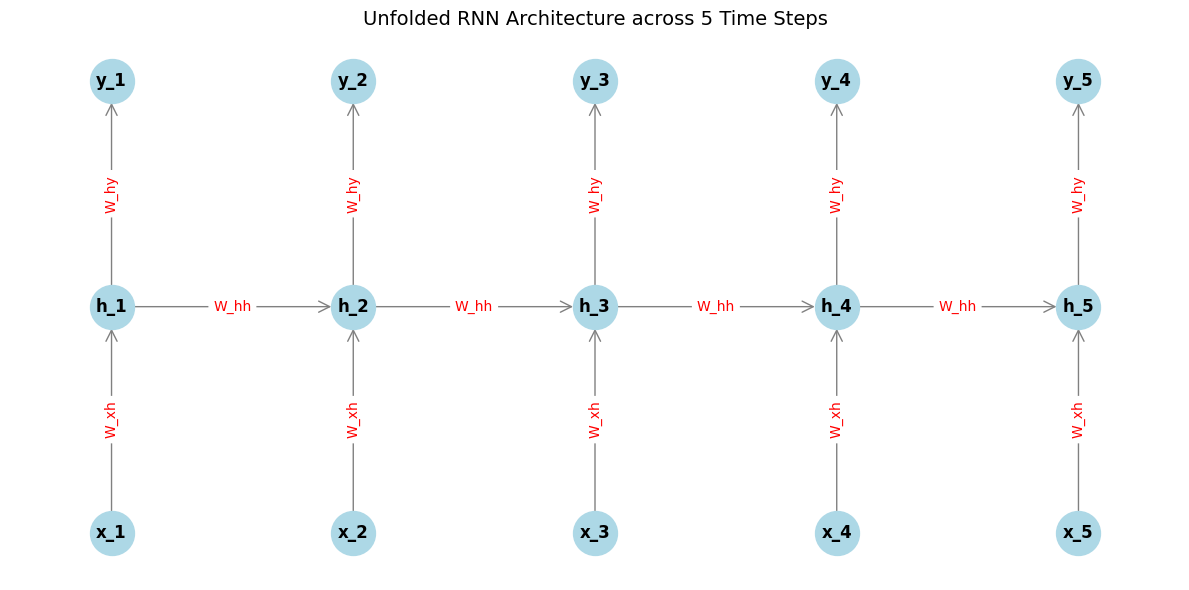

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

# Positions for visual organization
pos = {}

# Add nodes and construct layers
for t in range(1, time_steps + 1):
    x_node = f"x_{t}"
    h_node = f"h_{t}"
    y_node = f"y_{t}"

    G.add_node(x_node)
    G.add_node(h_node)
    G.add_node(y_node)

    # Positioning layers visually: inputs at y=0, hidden at y=1, outputs at y=2
    pos[x_node] = (t * 2, 0)
    pos[h_node] = (t * 2, 1)
    pos[y_node] = (t * 2, 2)

    # Vertical Edges
    G.add_edge(x_node, h_node, label="W_xh")
    G.add_edge(h_node, y_node, label="W_hy")

    # Horizontal Recurrent Edges
    if t > 1:
        prev_h_node = f"h_{t-1}"
        G.add_edge(prev_h_node, h_node, label="W_hh")

# Drawing configuration
plt.figure(figsize=(12, 6))
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1000)
nx.draw_networkx_labels(G, pos, font_weight='bold')

# Draw edges
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='gray', node_size=1000)

# Label weights on edges
edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_color='red')

plt.title("Unfolded RNN Architecture across 5 Time Steps", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

# Task 5: Plotting the Hidden State Values across Time Steps
Finally, we will visualize how each of the 3 units in our hidden state evolves over the 5 time steps.

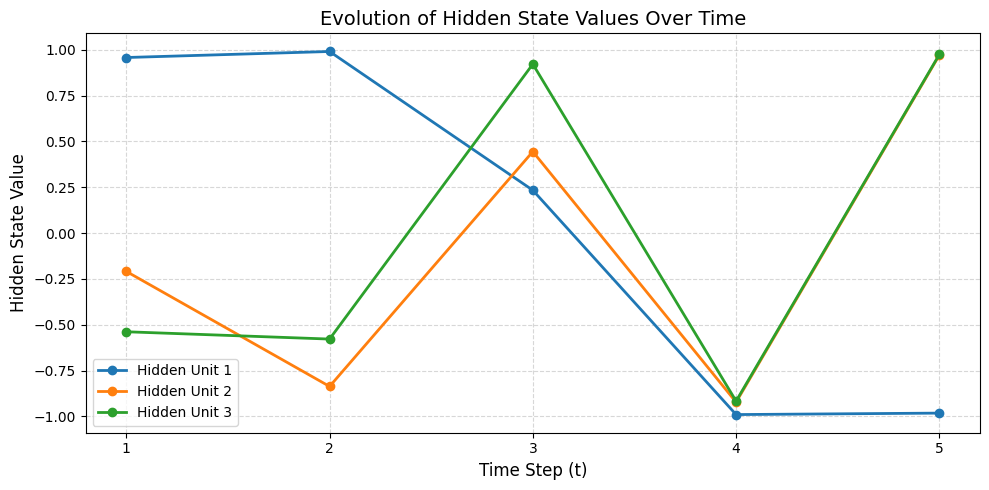

In [4]:
plt.figure(figsize=(10, 5))
time_axes = np.arange(1, time_steps + 1)

for i in range(hidden_units):
    plt.plot(time_axes, manual_h[:, i], marker='o', linewidth=2, label=f'Hidden Unit {i+1}')

plt.title('Evolution of Hidden State Values Over Time', fontsize=14)
plt.xlabel('Time Step (t)', fontsize=12)
plt.ylabel('Hidden State Value', fontsize=12)
plt.xticks(time_axes)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()